In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split , StratifiedKFold, cross_val_score,cross_validate
from sklearn.ensemble import RandomForestClassifier,HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from pathlib import Path
import joblib




In [ ]:
df = pd.read_csv("../data/raw/banana_iot_model_ready.csv")

print(df.shape)
print(df.columns.tolist())
print(df["quality"].value_counts())

(4500, 14)
['id', 'temperature', 'humidity', 'mq2_raw', 'mq2_voltage', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw', 'quality', 'hour', 'day_of_week', 'storage_day', 'light_bright']
quality
moyen      1500
mauvais    1500
bon        1500
Name: count, dtype: int64


In [3]:
features = [
    "temperature",
    "humidity",
    "mq2_raw",
    "mq2_voltage",
    "fc28_raw",
    "liquid_detected",
    "motion_detected",
    "ldr_raw",
    "hour",
    "day_of_week",
    "storage_day",
    "light_bright",
]

df.groupby("quality")[features].mean().round(2)

,temperature,humidity,mq2_raw,mq2_voltage,fc28_raw,liquid_detected,motion_detected,ldr_raw,hour,day_of_week,storage_day,light_bright
quality,,,,,,,,,,,,
bon,13.60,90.02,796.83,0.64,3009.55,0.00,0.36,2106.13,11.68,2.90,7.39,0.51
mauvais,14.31,68.02,1740.82,1.40,1905.22,0.39,0.35,2094.89,11.61,3.10,33.24,0.52
moyen,13.74,88.11,1253.17,1.01,2409.48,0.08,0.35,2152.94,11.55,3.11,19.98,0.55


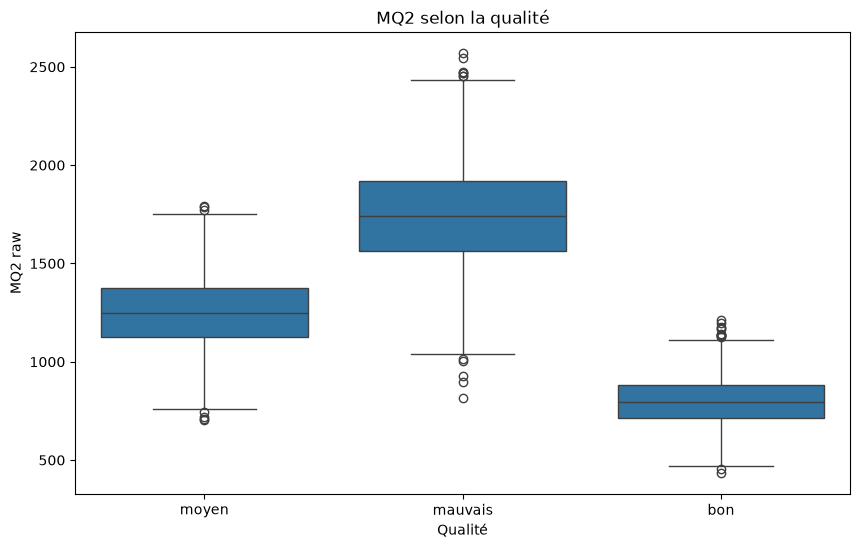

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="quality",
    y="mq2_raw"
)

plt.title("MQ2 selon la qualité")
plt.xlabel("Qualité")
plt.ylabel("MQ2 raw")

plt.show()

Dans le dataset de développement, l'augmentation de la réponse brute du capteur MQ2 est associée aux niveaux de dégradation de la banane.

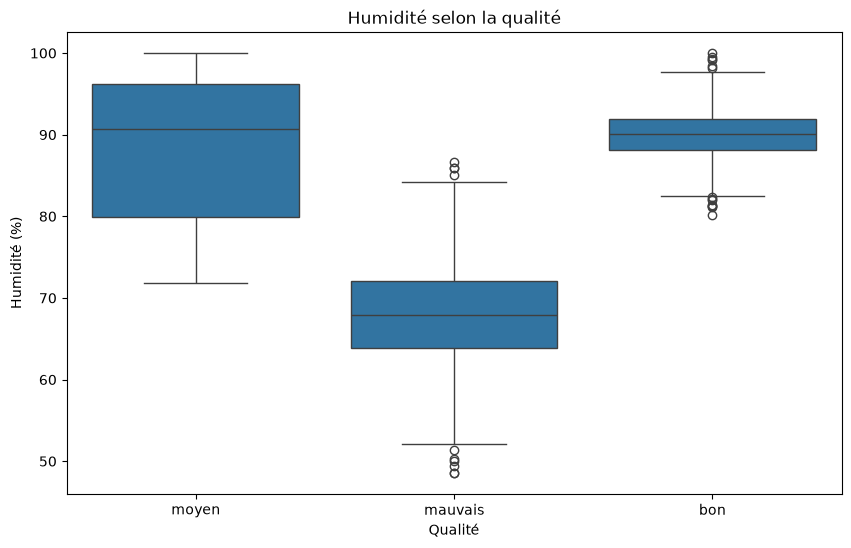

In [5]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="quality",
    y="humidity"
)

plt.title("Humidité selon la qualité")
plt.xlabel("Qualité")
plt.ylabel("Humidité (%)")

plt.show()

Bon : humidité centrée autour de 90 %, ce qui correspond bien à la plage optimale 85–95 %.
Moyen : humidité globalement élevée mais plus dispersée, avec des valeurs pouvant sortir de la zone optimale.
Mauvais : forte baisse de l'humidité, centrée autour de 68 %, ce qui correspond à une situation de dessèchement.

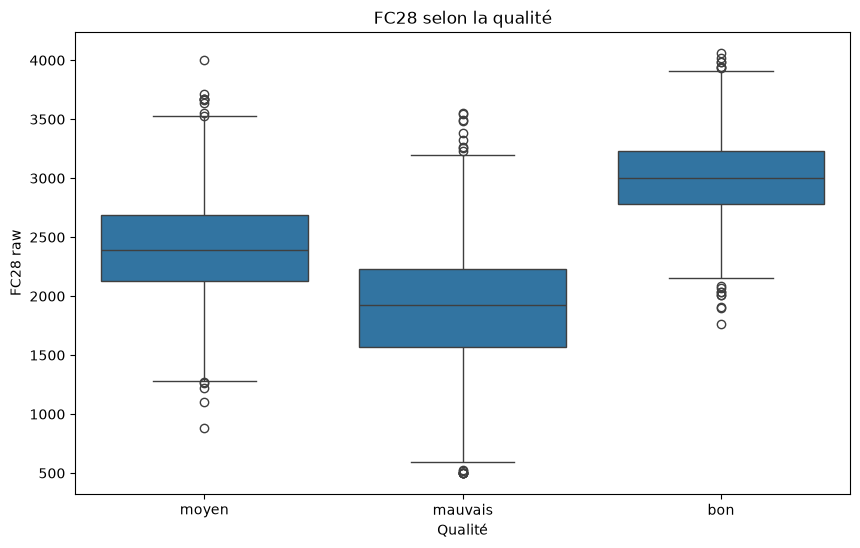

In [6]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="quality",
    y="fc28_raw"
)

plt.title("FC28 selon la qualité")
plt.xlabel("Qualité")
plt.ylabel("FC28 raw")

plt.show()

Ce graphique représente la distribution des valeurs d'un autre capteur (FC28 raw) en fonction de trois catégories de qualité :   Moyen : La médiane se situe autour de 2 400, et la boîte s'étend globalement d'environ 2 120 à 2 680. Les moustaches et les valeurs aberrantes (outliers) s'étendent de près de 900 jusqu'à environ 4 000.   Mauvais : Cette catégorie présente les valeurs de FC28 raw les plus faibles, avec une médiane proche de 1 920 et une boîte comprise entre environ 1 560 et 2 220. On y observe plusieurs valeurs aberrantes autour de 500 ainsi qu'au-dessus de 3 200.   Bon : Cette catégorie affiche les valeurs de FC28 raw les plus élevées, avec une médiane autour de 3 000 et une boîte s'étendant d'environ 2 780 à 3 220. Les moustaches et les points aberrants vont d'environ 1 750 jusqu'à plus de 4 000.  

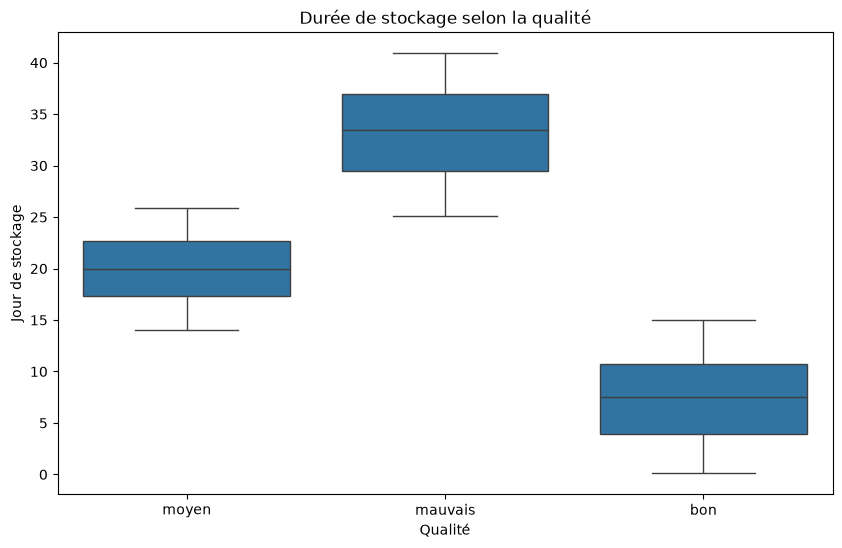

In [7]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="quality",
    y="storage_day"
)

plt.title("Durée de stockage selon la qualité")
plt.xlabel("Qualité")
plt.ylabel("Jour de stockage")

plt.show()

Ce graphique montre la distribution de la durée de stockage (exprimée en jours) en fonction de trois catégories de qualité :   Moyen : La médiane se situe autour de 20 jours. La boîte s'étend globalement de 17,5 à 22,5 jours, avec des moustaches allant d'environ 14 à près de 26 jours.   Mauvais : Cette catégorie présente les durées de stockage les plus longues, avec une médiane proche de 33,5 jours. La boîte s'étale environ de 29,5 à 37 jours, et les moustaches couvrent une amplitude allant de 25 à un peu plus de 40 jours.   Bon : Cette catégorie affiche les durées de stockage les plus courtes, avec une médiane d'environ 7,5 jours. La boîte se situe entre 4 et près de 11 jours, et les moustaches s'étendent de 0 à 15 jours.   

In [8]:
sensor_features = [
    "temperature",
    "humidity",
    "mq2_raw",
    "mq2_voltage",
    "fc28_raw",
    "liquid_detected",
    "motion_detected",
    "ldr_raw",
    "light_bright",
]

temporal_features = [
    "hour",
    "day_of_week",
    "storage_day",
]

print("Variables capteurs :", sensor_features)
print("Variables temporelles :", temporal_features)

Variables capteurs : ['temperature', 'humidity', 'mq2_raw', 'mq2_voltage', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw', 'light_bright']
Variables temporelles : ['hour', 'day_of_week', 'storage_day']


In [9]:
sensor_features = [
    "temperature",
    "humidity",
    "mq2_raw",
    "mq2_voltage",
    "fc28_raw",
    "liquid_detected",
    "motion_detected",
    "ldr_raw",
    "light_bright",
]

sensor_by_quality = (
    df.groupby("quality")[sensor_features]
    .mean()
    .round(2)
)

sensor_by_quality

,temperature,humidity,mq2_raw,mq2_voltage,fc28_raw,liquid_detected,motion_detected,ldr_raw,light_bright
quality,,,,,,,,,
bon,13.60,90.02,796.83,0.64,3009.55,0.00,0.36,2106.13,0.51
mauvais,14.31,68.02,1740.82,1.40,1905.22,0.39,0.35,2094.89,0.52
moyen,13.74,88.11,1253.17,1.01,2409.48,0.08,0.35,2152.94,0.55


Les variables mq2_raw et mq2_voltage racontent pratiquement la même information, puisque la tension est calculée à partir de la valeur brute du MQ2.
motion_detected, ldr_raw et light_bright ont des moyennes très proches entre les trois classes.
Par exemple :
- motion_detected : 0.36 → 0.35 → 0.35
- ldr_raw : 2106 → 2095 → 2153
- light_bright : 0.51 → 0.52 → 0.55
Dans notre dataset synthétique, ces variables ne semblent donc pas apporter beaucoup d'information pour prédire la qualité.

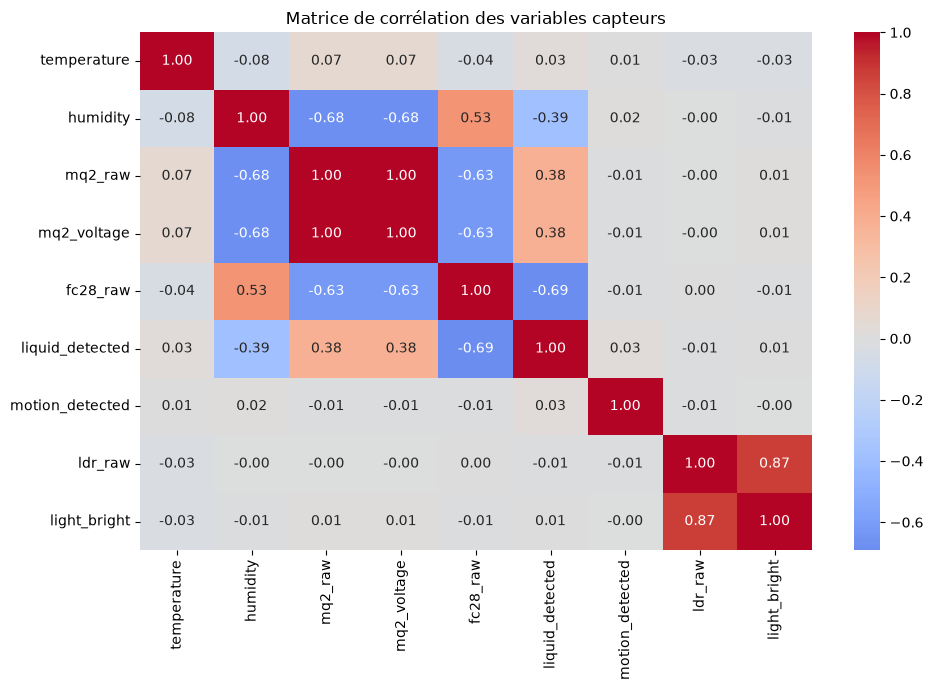

In [12]:


correlation = df[sensor_features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matrice de corrélation des variables capteurs")
plt.tight_layout()
plt.show()

"Matrice de corrélation des variables capteurs". Elle présente les coefficients de corrélation de Pearson entre différentes variables mesurées par des capteurs :   Corrélations fortes (positives ou négatives) :Une corrélation parfaite de 1,00 (ou -1,00) s'observe logiquement entre les variables identiques, ainsi qu'entre mq2_raw et mq2_voltage, et entre ldr_raw et light_bright (0,87).   Une forte corrélation positive de 0,53 existe entre fc28_raw et humidity.   Des corrélations négatives notables apparaissent entre humidity et mq2_raw / mq2_voltage (-0,68), ainsi qu'entre fc28_raw et liquid_detected (-0,69) ou mq2_raw (-0,63).   Corrélations faibles ou nulles :La variable temperature présente des coefficients très proches de 0 (généralement entre -0,08 et 0,07) avec la quasi-totalité des autres capteurs, ce qui indique une absence de relation linéaire directe.   De même, motion_detected montre des corrélations presque nulles (entre -0,01 et 0,03) avec l'ensemble des autres variables mesurées.   

In [13]:
sensor_features = [
    "temperature",
    "humidity",
    "mq2_raw",
    "mq2_voltage",
    "fc28_raw",
    "liquid_detected",
    "motion_detected",
    "ldr_raw",
    "light_bright",
]

sensor_plus_time_features = sensor_features + [
    "storage_day"
]

X_sensors = df[sensor_features]
X_sensors_time = df[sensor_plus_time_features]
y = df["quality"]

print("Configuration 1 — capteurs uniquement")
print(X_sensors.columns.tolist())

print("\nConfiguration 2 — capteurs + storage_day")
print(X_sensors_time.columns.tolist())

print("\nTarget :", y.name)
print("Nombre d'observations :", len(df))

Configuration 1 — capteurs uniquement
['temperature', 'humidity', 'mq2_raw', 'mq2_voltage', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw', 'light_bright']

Configuration 2 — capteurs + storage_day
['temperature', 'humidity', 'mq2_raw', 'mq2_voltage', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw', 'light_bright', 'storage_day']

Target : quality
Nombre d'observations : 4500


In [15]:
# Même séparation pour les deux expériences
X_train_sensor, X_test_sensor, y_train, y_test = train_test_split(
    X_sensors,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

X_train_time, X_test_time, _, _ = train_test_split(
    X_sensors_time,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# Modèle A : capteurs uniquement
model_sensors = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
)

model_sensors.fit(X_train_sensor, y_train)
pred_sensors = model_sensors.predict(X_test_sensor)

# Modèle B : capteurs + storage_day
model_sensors_time = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
)

model_sensors_time.fit(X_train_time, y_train)
pred_sensors_time = model_sensors_time.predict(X_test_time)

# Comparaison
accuracy_sensors = accuracy_score(y_test, pred_sensors)
accuracy_sensors_time = accuracy_score(y_test, pred_sensors_time)

print("=== MODÈLE A : CAPTEURS UNIQUEMENT ===")
print(f"Accuracy : {accuracy_sensors:.4f}")
print(classification_report(y_test, pred_sensors))

print("\n=== MODÈLE B : CAPTEURS + STORAGE_DAY ===")
print(f"Accuracy : {accuracy_sensors_time:.4f}")
print(classification_report(y_test, pred_sensors_time))

=== MODÈLE A : CAPTEURS UNIQUEMENT ===
Accuracy : 0.9867
              precision    recall  f1-score   support

         bon       0.99      0.98      0.99       300
     mauvais       0.99      0.99      0.99       300
       moyen       0.98      0.98      0.98       300

    accuracy                           0.99       900
   macro avg       0.99      0.99      0.99       900
weighted avg       0.99      0.99      0.99       900


=== MODÈLE B : CAPTEURS + STORAGE_DAY ===
Accuracy : 0.9989
              precision    recall  f1-score   support

         bon       1.00      1.00      1.00       300
     mauvais       1.00      1.00      1.00       300
       moyen       1.00      1.00      1.00       300

    accuracy                           1.00       900
   macro avg       1.00      1.00      1.00       900
weighted avg       1.00      1.00      1.00       900



In [16]:
core_sensor_features = [
    "temperature",
    "humidity",
    "mq2_raw",
    "fc28_raw",
    "liquid_detected",
    "motion_detected",
    "ldr_raw",
]

X_core = df[core_sensor_features]

X_train_core, X_test_core, y_train_core, y_test_core = train_test_split(
    X_core,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

model_core = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
)

model_core.fit(X_train_core, y_train_core)

pred_core = model_core.predict(X_test_core)

accuracy_core = accuracy_score(y_test_core, pred_core)

print("=== MODÈLE C : CAPTEURS BRUTS UNIQUEMENT ===")
print(f"Accuracy : {accuracy_core:.4f}")
print(classification_report(y_test_core, pred_core))

=== MODÈLE C : CAPTEURS BRUTS UNIQUEMENT ===
Accuracy : 0.9878
              precision    recall  f1-score   support

         bon       0.99      0.99      0.99       300
     mauvais       0.99      0.99      0.99       300
       moyen       0.98      0.98      0.98       300

    accuracy                           0.99       900
   macro avg       0.99      0.99      0.99       900
weighted avg       0.99      0.99      0.99       900



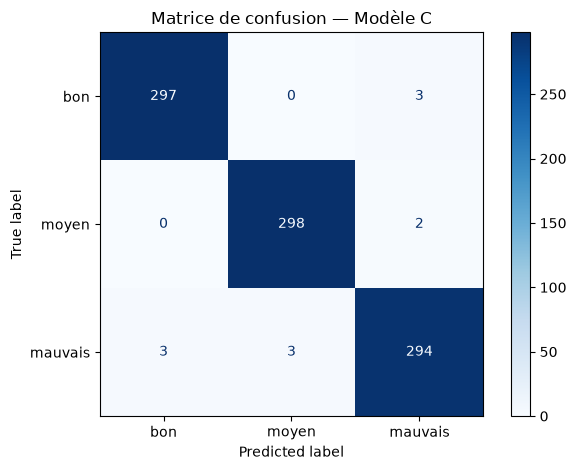

Importance des variables :
mq2_raw            0.3750
humidity           0.2940
temperature        0.2022
fc28_raw           0.1007
liquid_detected    0.0155
ldr_raw            0.0110
motion_detected    0.0016
dtype: float64


In [18]:
# 1. Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test_core,
    pred_core,
    display_labels=["bon", "moyen", "mauvais"],
    cmap="Blues"
)

plt.title("Matrice de confusion — Modèle C")
plt.tight_layout()
plt.show()


# 2. Importance des variables
feature_importance = (
    pd.Series(
        model_core.feature_importances_,
        index=core_sensor_features
    )
    .sort_values(ascending=False)
)

print("Importance des variables :")
print(feature_importance.round(4))

Dans le jeu de données utilisé pour le développement, la réponse brute du capteur MQ2 (mq2_raw) constitue la variable la plus importante pour la classification, suivie de l'humidité et de la température. Cette relation devra être vérifiée expérimentalement sur les données réelles acquises par le système IoT.

Validation Coroisée

In [20]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

cv_scores = cross_val_score(
    RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
    ),
    X_core,
    y,
    cv=cv,
    scoring="accuracy",
)

print("Scores des 5 folds :")
print(cv_scores.round(4))

print(f"\nAccuracy moyenne : {cv_scores.mean():.4f}")
print(f"Écart-type       : {cv_scores.std():.4f}")
print(
    f"Intervalle approximatif : "
    f"{cv_scores.mean() - cv_scores.std():.4f} "
    f"à {cv_scores.mean() + cv_scores.std():.4f}"
)

Scores des 5 folds :
[0.9867 0.9878 0.9889 0.9822 0.9933]

Accuracy moyenne : 0.9878
Écart-type       : 0.0036
Intervalle approximatif : 0.9842 à 0.9914


Le Random Forest basé uniquement sur les variables capteurs atteint une accuracy moyenne de 98,78 % ± 0,36 % en validation croisée stratifiée à 5 folds sur le dataset synthétique.

In [22]:
cv_results = cross_validate(
    RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
    ),
    X_core,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro",
    },
    n_jobs=-1,
)

print("=== VALIDATION CROISÉE — MODÈLE C ===")

for metric in [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro",
]:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric:20s} : "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

=== VALIDATION CROISÉE — MODÈLE C ===
accuracy             : 0.9878 ± 0.0036
precision_macro      : 0.9878 ± 0.0036
recall_macro         : 0.9878 ± 0.0036
f1_macro             : 0.9878 ± 0.0036


Le modèle Random Forest utilisant uniquement les mesures brutes des capteurs (temperature, humidity, mq2_raw, fc28_raw, liquid_detected, motion_detected et ldr_raw) obtient une performance moyenne de 98,78 % en validation croisée stratifiée à 5 folds, avec un écart-type de 0,36 %. Le F1-score macro est également de 98,78 % ± 0,36 %, indiquant une performance homogène entre les trois classes de qualité.

In [24]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=200,
        random_state=42,
    ),
}

comparison_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_core,
        y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro",
        },
        n_jobs=-1,
    )

    comparison_results.append({
        "model": name,
        "accuracy_mean": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "precision_mean": scores["test_precision_macro"].mean(),
        "recall_mean": scores["test_recall_macro"].mean(),
        "f1_mean": scores["test_f1_macro"].mean(),
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df.round(4)

,model,accuracy_mean,accuracy_std,precision_mean,recall_mean,f1_mean
0,Random Forest,0.9878,0.0036,0.9878,0.9878,0.9878
1,HistGradientBoosting,0.9896,0.0019,0.9896,0.9896,0.9896


HistGradientBoosting présente une performance légèrement supérieure et une meilleure stabilité que Random Forest sur le jeu de données synthétique utilisé.

=== HISTGRADIENTBOOSTING — MODÈLE C ===
Accuracy : 0.9878

Classification report :
              precision    recall  f1-score   support

         bon       0.99      0.99      0.99       300
     mauvais       0.99      0.99      0.99       300
       moyen       0.98      0.98      0.98       300

    accuracy                           0.99       900
   macro avg       0.99      0.99      0.99       900
weighted avg       0.99      0.99      0.99       900



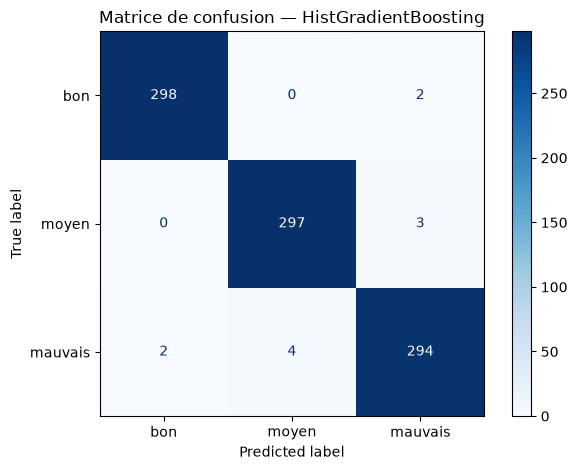

In [26]:
# Modèle final candidat
final_model = HistGradientBoostingClassifier(
    max_iter=200,
    random_state=42,
)

# Entraînement
final_model.fit(X_train_core, y_train_core)

# Prédictions
final_predictions = final_model.predict(X_test_core)

# Accuracy
final_accuracy = accuracy_score(
    y_test_core,
    final_predictions,
)

print("=== HISTGRADIENTBOOSTING — MODÈLE C ===")
print(f"Accuracy : {final_accuracy:.4f}")

print("\nClassification report :")
print(
    classification_report(
        y_test_core,
        final_predictions,
    )
)

# Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test_core,
    final_predictions,
    display_labels=["bon", "moyen", "mauvais"],
    cmap="Blues",
)

plt.title("Matrice de confusion — HistGradientBoosting")
plt.tight_layout()
plt.show()

Pour notre dataset synthétique, HistGradientBoosting est un bon candidat final :
- Accuracy CV : 98,96 % ± 0,19 %
- Accuracy sur le test : 98,78 %
- Les trois classes sont correctement reconnues à ~98–99 %.
- Il utilise uniquement les capteurs principaux, sans storage_day, donc on évite le raccourci évident introduit par cette variable.

In [28]:
# Features réellement utilisées par le modèle
MODEL_FEATURES = [
    "temperature",
    "humidity",
    "mq2_raw",
    "fc28_raw",
    "liquid_detected",
    "motion_detected",
    "ldr_raw",
]

# Dossier de sauvegarde
MODEL_DIR = Path("../models/development")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Sauvegarde du modèle + métadonnées
model_artifact = {
    "model": final_model,
    "features": MODEL_FEATURES,
    "target": "quality",
    "model_name": "HistGradientBoostingClassifier",
    "version": "1.0.0",
}

model_path = MODEL_DIR / "banana_quality_histgradientboosting.joblib"

joblib.dump(model_artifact, model_path)

print(f"Modèle sauvegardé : {model_path}")

Modèle sauvegardé : ..\models\development\banana_quality_histgradientboosting.joblib


In [29]:
# Rechargement du modèle sauvegardé
loaded_artifact = joblib.load(
    "../models/development/banana_quality_histgradientboosting.joblib"
)

loaded_model = loaded_artifact["model"]
loaded_features = loaded_artifact["features"]

print("Modèle chargé :", loaded_artifact["model_name"])
print("Version :", loaded_artifact["version"])
print("Features :", loaded_features)

# Une observation IoT de test
iot_sample = pd.DataFrame([{
    "temperature": 13.6,
    "humidity": 90.0,
    "mq2_raw": 800,
    "fc28_raw": 3000,
    "liquid_detected": 0,
    "motion_detected": 1,
    "ldr_raw": 2100,
}])

# Respecter exactement l'ordre des features du modèle
iot_sample = iot_sample[loaded_features]

# Prédiction
prediction = loaded_model.predict(iot_sample)[0]

print("\nPrédiction :", prediction)

Modèle chargé : HistGradientBoostingClassifier
Version : 1.0.0
Features : ['temperature', 'humidity', 'mq2_raw', 'fc28_raw', 'liquid_detected', 'motion_detected', 'ldr_raw']

Prédiction : bon


In [30]:
from banana_ml.features.iot_features import prepare_iot_features

esp32_data = {
    "id": 1,
    "device_id": "esp32-001",
    "temperature": 13.6,
    "humidity": 90.0,
    "mq2_raw": 800,
    "mq2_voltage": 0.64,
    "fc28_raw": 3000,
    "liquid_detected": 0,
    "motion_detected": 1,
    "ldr_raw": 2100,
    "light_label": "bright",
    "detected_at": "2026-10-06 02:00:00",
}

X_iot = prepare_iot_features(esp32_data)

print(X_iot)

   temperature  humidity  mq2_raw  fc28_raw  liquid_detected  motion_detected  \
0         13.6      90.0      800      3000                0                1   

   ldr_raw  
0     2100  


In [31]:
prediction = loaded_model.predict(X_iot)[0]

print("Qualité prédite :", prediction)

Qualité prédite : bon


In [32]:
# Trois scénarios IoT de test
test_cases = {
    "bon_attendu": {
        "temperature": 13.6,
        "humidity": 90.0,
        "mq2_raw": 800,
        "fc28_raw": 3000,
        "liquid_detected": 0,
        "motion_detected": 1,
        "ldr_raw": 2100,
    },
    "moyen_attendu": {
        "temperature": 15.5,
        "humidity": 80.0,
        "mq2_raw": 1250,
        "fc28_raw": 2400,
        "liquid_detected": 0,
        "motion_detected": 1,
        "ldr_raw": 2100,
    },
    "mauvais_attendu": {
        "temperature": 20.5,
        "humidity": 68.0,
        "mq2_raw": 1750,
        "fc28_raw": 1500,
        "liquid_detected": 1,
        "motion_detected": 1,
        "ldr_raw": 2100,
    },
}

for expected, data in test_cases.items():
    X_test_iot = prepare_iot_features(data)

    prediction = loaded_model.predict(X_test_iot)[0]

    print(f"{expected:20} → prédiction : {prediction}")

bon_attendu          → prédiction : bon
moyen_attendu        → prédiction : moyen
mauvais_attendu      → prédiction : mauvais


In [33]:
from banana_ml.models.predictor import predict_quality


esp32_data = {
    "id": 1,
    "device_id": "esp32-001",
    "temperature": 13.6,
    "humidity": 90.0,
    "mq2_raw": 800,
    "mq2_voltage": 0.64,
    "fc28_raw": 3000,
    "liquid_detected": 0,
    "motion_detected": 1,
    "ldr_raw": 2100,
    "light_label": "bright",
    "detected_at": "2026-10-06 02:00:00",
}

prediction = predict_quality(esp32_data)

print("Qualité prédite :", prediction)

Qualité prédite : bon


In [34]:
from banana_ml.data.validation import validate_iot_measurement

valid_data = {
    "temperature": 13.6,
    "humidity": 90.0,
    "mq2_raw": 800,
    "fc28_raw": 3000,
    "liquid_detected": 0,
    "motion_detected": 1,
    "ldr_raw": 2100,
}

validate_iot_measurement(valid_data)

print("Mesure IoT valide")

Mesure IoT valide


In [35]:
invalid_data = {
    "temperature": 13.6,
    "humidity": 90.0,
    "mq2_raw": 5000,  # invalide : maximum 4095
    "fc28_raw": 3000,
    "liquid_detected": 0,
    "motion_detected": 1,
    "ldr_raw": 2100,
}

try:
    validate_iot_measurement(invalid_data)
    print("Mesure acceptée")
except ValueError as error:
    print("Mesure rejetée :", error)

Mesure rejetée : mq2_raw doit être compris entre 0 et 4095.
